# Flood Mapping in Emilia-Romagna with Sentinel-1 SAR

We map the **May 2023 Emilia-Romagna flood** (Bassa Romagna: Lugo, Conselice, Bagnacavallo) with **Sentinel-1 GRD (VV + VH, σ⁰ in dB)** and compare two approaches against the **Copernicus EMS EMSR664** reference map:
- **Otsu thresholding** → (a) post-event image only · (b) post − pre change detection
- a **small U-Net written from scratch in PyTorch**, trained on **Sen1Floods11 (hand-labeled)** and applied **zero-shot** to Emilia-Romagna (domain shift)

## Decision log

| # | Decision | Choice | Rejected | Section |
|---|---|---|---|---|
| 1 | Case study | Emilia-Romagna, May 2023 (EMSR664) | Liguria Nov 2014 (EMSR112) · Emilia-Romagna Sep 2024 / Oct 2024 / Mar 2025 | 1 |
| 2 | Dead end: global Otsu | – | one threshold on the whole image (30% water, class imbalance) | 5 |
| 3 | Otsu threshold | tile-based Otsu (most contrasted tiles) | global Otsu | 5 |
| 4 | Speckle filter | median 5 × 5, size fixed a priori | no filter · mean filter · Lee filter | 5 |
| 5 | Normalization | mean / std per band, from train chips only | statistics from all the data | 7 |
| 6 | U-Net size | 3 steps down, 16 → 128 channels (~0.5 M weights) | original U-Net, 64 → 1024 channels (~31 M weights) | 8 |
| 7 | Loss | BCE without −1 pixels, with pos_weight | plain BCE · Dice loss | 9 |
| 8 | Where to train | CPU, 15 epochs (~4 min each) | Google Colab GPU | 9 |
| 9 | Dead end: pos_weight 9.5 (land / water) | – | too many false alarms, valid IoU unstable (0.31–0.58) | 9 |
| 10 | pos_weight | 3 (≈ √9.5) | 9.5 | 9 |

## 0. Setup

In [40]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [41]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import skimage
import torch
import openeo

SEED = 4
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")        # GeoTIFF, EMS vectors, Sen1Floods11 (not on GitHub)
MODELS_DIR = Path("models")    # U-Net weights (not on GitHub)
FIGURES_DIR = Path("figures")  # PNG and GIF for the README
for folder in [DATA_DIR, MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(exist_ok=True)

print("numpy", np.__version__, "| torch", torch.__version__, "| openeo", openeo.__version__, "| rasterio", rasterio.__version__)

numpy 2.5.4 | torch 2.15.0+cpu | openeo 0.54.0 | rasterio 1.5.2


In [42]:
# GPU check → decides where we train the U-Net (section 10)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)
print("CPU threads:", torch.get_num_threads())

CUDA available: False
Device: cpu
CPU threads: 6


### Copernicus Data Space Ecosystem login

We download Sentinel-1 through **openEO** on the Copernicus Data Space Ecosystem (CDSE). The first login opens a browser page, then the token is cached.

In [43]:
OPENEO_URL = "openeo.dataspace.copernicus.eu"

connection = openeo.connect(OPENEO_URL).authenticate_oidc()

print("Sentinel-1 GRD available:", "SENTINEL1_GRD" in connection.list_collection_ids())
print("Logged in as:", connection.describe_account()["name"])  # only the name → no email in the public repo

Authenticated using refresh token.
Sentinel-1 GRD available: True
Logged in as: Daniel Di Somma


## 1. Area and event

Originally I wanted to cover floods on the Liguria region, but since the morphology is more complicated, the results would be less clear.

That's why we're analyzing **Emilia-Romagna** in **May 2023**, where persistent rain hit the region in **two waves**, resulting in catastrophic events such as floods, river overflows and landslides:
- **1–3 May 2023**: first heavy rain, rivers overflow on **2–3 May** (Copernicus EMS activation **EMSR659**)
- **15–17 May 2023**: second, even stronger rain on soil that was already saturated → more than 20 rivers overflow on **16–17 May**, the plain around Lugo, Conselice and Bagnacavallo is flooded for weeks


### Which Sentinel-1 images we use

We searched the Sentinel-1 GRD passes over **Lugo** between 25 April and 25 May 2023 in the **Copernicus Browser**.

| Date | Time (UTC) | Orbit direction | Use |
|---|---|---|---|
| 28/04/2023 | ~05:19 | descending | **pre-event** |
| 29/04/2023 | ~17:06 | ascending | – |
| 10/05/2023 | ~05:19 | descending | problem: water from the 2–3 May flood is still there |
| 11/05/2023 | ~17:06 | ascending | – |
| **22/05/2023** | **~05:19** | descending | **post-event** |
| 23/05/2023 | ~17:06 | ascending | – |

In 2023 only **Sentinel-1A** was flying, so the same orbit comes back every **12 days**. Pre and post from the same orbit have the **same viewing geometry** and can be compared pixel by pixel. We pick **22 May** (first descending pass after the 16–17 May peak) and **28 April** (last pass before the May floods).

As reference we use the EMS product **EMSR664 AOI01 DEL MONIT03**, made from a **COSMO-SkyMed** image of **21 May, 16:50 UTC**, about **12 hours before** our Sentinel-1 pass.

In [44]:
# EMS flood map, downloaded by hand from the EMSR664 page and unzipped into data/
EMS_DIR = DATA_DIR / "EMSR664_AOI01_DEL_MONIT03_v1"

flood_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_observedEventA_v1.shp")  # flooded areas
aoi_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_areaOfInterestA_v1.shp")   # mapped area

print("flood polygons:", len(flood_ems), "| CRS:", flood_ems.crs)
flood_ems.head()

flood polygons: 1245 | CRS: EPSG:4326


,event_type,obj_desc,det_method,notation,dmg_src_id,area,geometry
0,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.053375,"POLYGON ((12.11537 44.35073, 12.11537 44.35072..."
1,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.085192,"POLYGON ((12.12645 44.40939, 12.12648 44.40938..."
2,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.031632,"POLYGON ((11.96852 44.50582, 11.9685 44.50581,..."
3,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.063630,"POLYGON ((11.95884 44.55308, 11.95882 44.55303..."
4,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.754732,"POLYGON ((12.02744 44.43376, 12.02746 44.43369..."


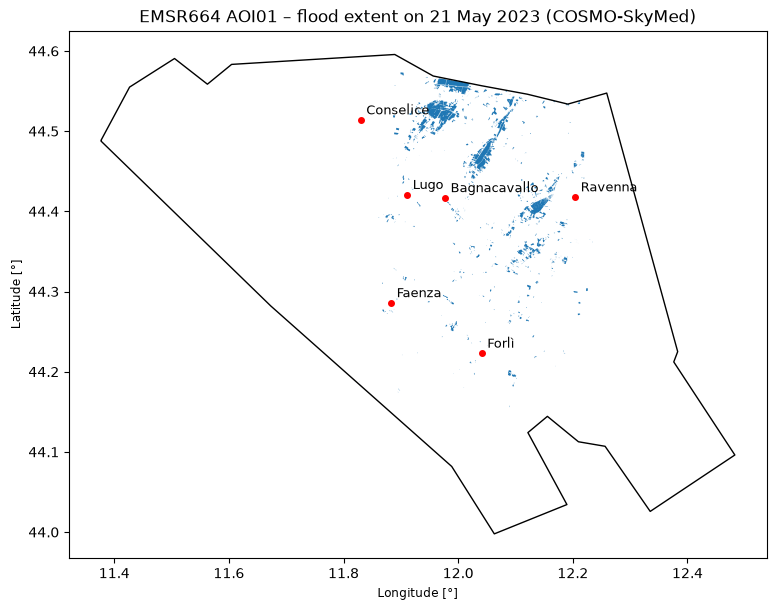

In [45]:
# Where is the water? EMS flood polygons inside the EMS area of interest
TOWNS = {                        # (longitude, latitude), only to orient ourselves on the map
    "Lugo": (11.911, 44.421),
    "Conselice": (11.830, 44.514),
    "Bagnacavallo": (11.977, 44.417),
    "Faenza": (11.883, 44.286),
    "Ravenna": (12.204, 44.418),
    "Forlì": (12.041, 44.223),
}

fig, ax = plt.subplots(figsize=(9, 8))
aoi_ems.boundary.plot(ax=ax, color="black", linewidth=1)   # contour of the area analysed by EMS
flood_ems.plot(ax=ax, color="tab:blue")                    # flooded areas on 21 May

for name, (lon, lat) in TOWNS.items():
    ax.plot(lon, lat, "o", color="red", markersize=4)
    ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9)

ax.set_title("EMSR664 AOI01 – flood extent on 21 May 2023 (COSMO-SkyMed)")
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
plt.show()

### What the map tells us

The water is concentrated in the **north-eastern plain** (Conselice, Lugo, Bagnacavallo), so instead of the whole EMS area (about 90 × 65 km) we download only a **rectangle around the flooded zone**.

In [46]:
from shapely.geometry import box

# Rectangle we will download from Sentinel-1 (degrees, EPSG:4326), same format openEO wants
BBOX = {"west": 11.85, "south": 44.30, "east": 12.20, "north": 44.58}

bbox_gdf = gpd.GeoDataFrame(geometry=[box(BBOX["west"], BBOX["south"], BBOX["east"], BBOX["north"])], crs="EPSG:4326")

# Degrees are not metres → reproject to UTM zone 32N (metres) to measure sizes and areas
bbox_utm = bbox_gdf.to_crs("EPSG:32632")
flood_utm = flood_ems.to_crs("EPSG:32632")
aoi_utm = aoi_ems.to_crs("EPSG:32632")

xmin, ymin, xmax, ymax = bbox_utm.total_bounds
print(f"BBOX size: {(xmax - xmin) / 1000:.1f} km x {(ymax - ymin) / 1000:.1f} km, about {(xmax - xmin) / 10:.0f} x {(ymax - ymin) / 10:.0f} pixels at 10 m")

water_in_bbox = flood_utm.clip(bbox_utm).area.sum()   # m², only the water inside the rectangle
print(f"Water fraction: BBOX {100 * water_in_bbox / bbox_utm.area.sum():.1f}% vs whole AOI {100 * flood_utm.area.sum() / aoi_utm.area.sum():.1f}%")

BBOX size: 29.0 km x 32.1 km, about 2900 x 3213 pixels at 10 m
Water fraction: BBOX 4.8% vs whole AOI 1.4%


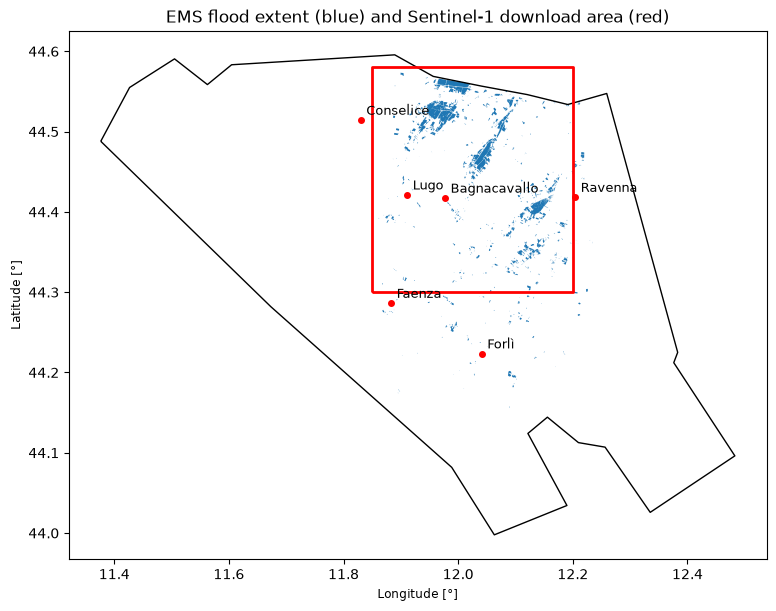

In [47]:
# Same map as before + the rectangle in red
fig, ax = plt.subplots(figsize=(9, 8))
aoi_ems.boundary.plot(ax=ax, color="black", linewidth=1)
flood_ems.plot(ax=ax, color="tab:blue")
bbox_gdf.boundary.plot(ax=ax, color="red", linewidth=2)   # area we download from Sentinel-1

for name, (lon, lat) in TOWNS.items():
    ax.plot(lon, lat, "o", color="red", markersize=4)
    ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9)

ax.set_title("EMS flood extent (blue) and Sentinel-1 download area (red)")
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
plt.show()

## 2. Sentinel-1 download with openEO

We download the pre (28 April) and post (22 May) images over our rectangle, bands **VV** and **VH**:
- **σ⁰ (sigma0-ellipsoid)**, not γ⁰ terrain-flattened: the U-Net will be trained on **Sen1Floods11**, which uses σ⁰. On a flat plain the difference is small anyway.
- **linear** values, converted to **dB** later in numpy.
- both images on the **same 10 m grid in UTM 32N**: our rectangle crosses the border between UTM zones 32 and 33, and without this the backend could pick a different grid for each image.

In [48]:
POST_DATE = "2023-05-22"
PRE_DATE = "2023-04-28"
UTM_EPSG = 32632    # UTM zone 32N, metres
PIXEL_SIZE = 10     # metres


def download_s1(date, output_file):
    """Download Sentinel-1 sigma0 (linear) VV + VH for one date over BBOX as a GeoTIFF."""
    if output_file.exists():                    # already downloaded → skip the ~5 min batch job
        print("already there:", output_file)
        return
    next_day = str(np.datetime64(date) + np.timedelta64(1, "D"))   # temporal extent: end date is excluded
    cube = connection.load_collection(
        "SENTINEL1_GRD",
        spatial_extent=BBOX,
        temporal_extent=[date, next_day],
        bands=["VV", "VH"],
    )
    cube = cube.sar_backscatter(coefficient="sigma0-ellipsoid")                    # calibration → sigma0
    cube = cube.resample_spatial(resolution=PIXEL_SIZE, projection=UTM_EPSG)       # same 10 m UTM grid for every image
    cube = cube.reduce_dimension(dimension="t", reducer="mean")                    # one date only → drop the time axis
    cube.execute_batch(outputfile=output_file, out_format="GTiff", title=f"S1 {date}")
    print("saved:", output_file)


POST_FILE = DATA_DIR / "s1_post_20230522.tif"
download_s1(POST_DATE, POST_FILE)

already there: data\s1_post_20230522.tif


In [49]:
# Same recipe for the pre-event image (same orbit 95, 12 days × 2 earlier)
PRE_FILE = DATA_DIR / "s1_pre_20230428.tif"
download_s1(PRE_DATE, PRE_FILE)

already there: data\s1_pre_20230428.tif


In [50]:
def read_s1_db(path):
    """Read a 2-band (VV, VH) sigma0 GeoTIFF and convert it from linear to dB."""
    with rasterio.open(path) as src:
        sigma0 = src.read()          # (2, rows, cols), linear power, band order VV, VH
        profile = src.profile        # grid info: CRS, transform, width, height → needed later for the EMS mask
    sigma0_db = 10 * np.log10(sigma0)
    return sigma0_db, profile


post_db, profile = read_s1_db(POST_FILE)   # (2, rows, cols)
pre_db, _ = read_s1_db(PRE_FILE)           # same grid → we keep only one profile

pre_db.shape, post_db.shape

((2, 3214, 2901), (2, 3214, 2901))

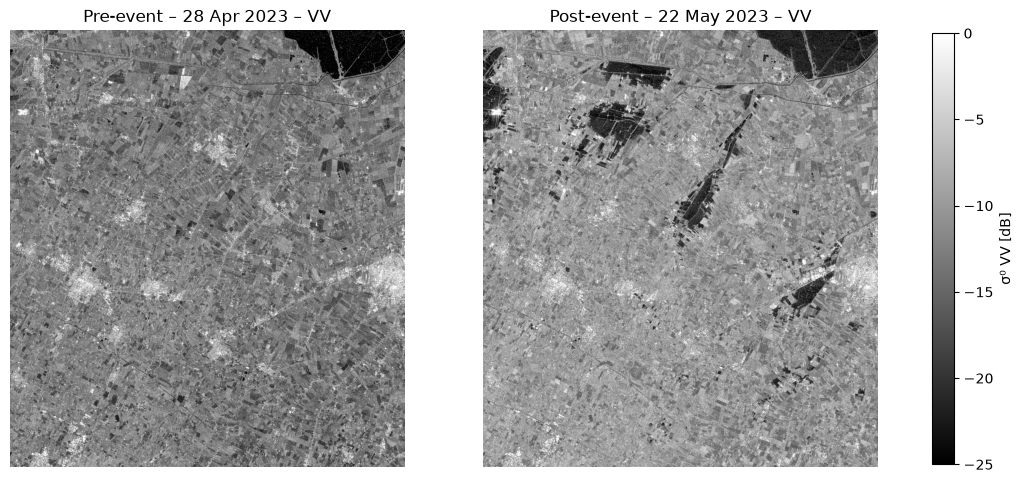

In [51]:
# Pre vs post, VV band, same fixed colour scale → same grey = same dB value in both images
VMIN, VMAX = -25, 0     # dB: calm water ≈ -25, buildings ≈ 0

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, image, title in zip(axes, [pre_db, post_db], ["Pre-event – 28 Apr 2023", "Post-event – 22 May 2023"]):
    im = ax.imshow(image[0], cmap="gray", vmin=VMIN, vmax=VMAX)   # image[0] = VV
    ax.set_title(f"{title} – VV")
    ax.axis("off")

fig.colorbar(im, ax=axes, shrink=0.7, label="σ⁰ VV [dB]")
plt.show()

## 3. Exploration

Before classifying, we look at the data up close (flooded fields, roads, **speckle**) and at the histograms of water and land.

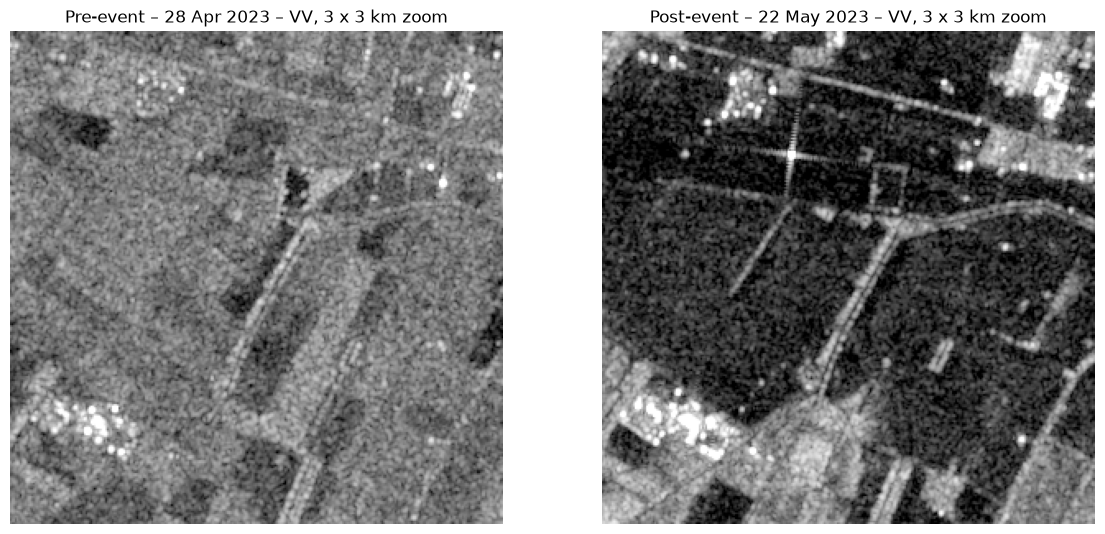

(300, 300)

In [52]:
# Zoom on a 3 x 3 km window (300 x 300 pixels) north of Lugo, inside the largest EMS flood polygon
ZOOM_ROWS = slice(550, 850)    # image rows    (north → south)
ZOOM_COLS = slice(800, 1100)   # image columns (west → east)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, title in zip(axes, [pre_db, post_db], ["Pre-event – 28 Apr 2023", "Post-event – 22 May 2023"]):
    ax.imshow(image[0, ZOOM_ROWS, ZOOM_COLS], cmap="gray", vmin=VMIN, vmax=VMAX)   # VV, only the window
    ax.set_title(f"{title} – VV, 3 x 3 km zoom")
    ax.axis("off")
plt.show()

post_db[0, ZOOM_ROWS, ZOOM_COLS].shape   # (300, 300)

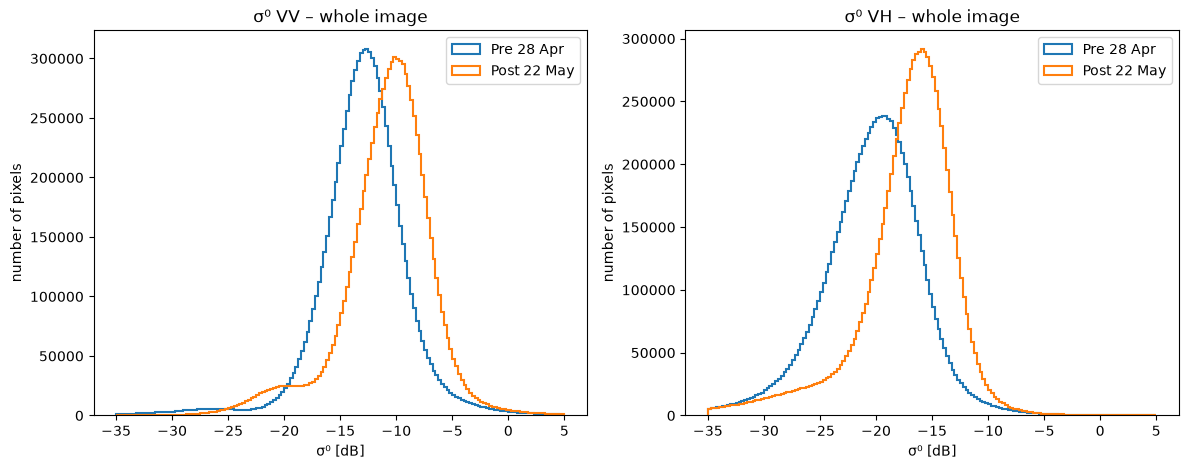

(9288497,)

In [53]:
# Histograms of the whole image: is there a separate "water" peak? (Otsu needs two peaks)
BINS = np.linspace(-35, 5, 161)   # dB, bins 0.25 dB wide

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for band, (ax, name) in enumerate(zip(axes, ["VV", "VH"])):
    for image, label in zip([pre_db, post_db], ["Pre 28 Apr", "Post 22 May"]):
        values = image[band].ravel()            # (rows * cols,) all pixels of one band in a 1D array
        values = values[np.isfinite(values)]    # drop -inf / NaN (log10 of 0 at the image border)
        ax.hist(values, bins=BINS, histtype="step", linewidth=1.5, label=label)
    ax.set_title(f"σ⁰ {name} – whole image")
    ax.set_xlabel("σ⁰ [dB]")
    ax.set_ylabel("number of pixels")
    ax.legend()
plt.show()

values.shape   # number of valid pixels (last band plotted)

In **VV** the flood shows up as a small **shoulder around −21 dB**; in **VH** water doesn't separate, so we threshold **VV**.

Dry land got about 3 dB brighter after the event (wet soil, growing crops), so post − pre won't be zero on dry land either.

## 4. Ground truth from EMS

We turn the EMS polygons into a raster on the Sentinel-1 grid (**rasterization**), with the same values as **Sen1Floods11**:
- **1** = flooded
- **0** = not flooded
- **−1** = ignored in the metrics: outside the EMS area, or **"Not Analysed – No data"** (outside the COSMO-SkyMed image)

In [54]:
from rasterio.features import rasterize

# Areas EMS did not analyse (outside the COSMO-SkyMed image), in UTM like the other layers
footprint_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_imageFootprintA_v1.shp")
not_analysed_utm = footprint_ems[footprint_ems["obj_type"] == "Not Analysed - No data"].to_crs(UTM_EPSG)

GRID_SHAPE = (profile["height"], profile["width"])   # (3214, 2901) rows, cols of the Sentinel-1 images
GRID_TRANSFORM = profile["transform"]                 # pixel (row, col) <-> UTM coordinates in metres


def polygons_to_mask(gdf):
    """1 where the pixel centre falls inside a polygon, 0 elsewhere, on the Sentinel-1 grid."""
    return rasterize(gdf.geometry, out_shape=GRID_SHAPE, transform=GRID_TRANSFORM,
                     fill=0, default_value=1, dtype="uint8")


flooded = polygons_to_mask(flood_utm)              # (rows, cols) 1 = EMS water
inside_aoi = polygons_to_mask(aoi_utm)             # (rows, cols) 1 = analysed by EMS
not_analysed = polygons_to_mask(not_analysed_utm)  # (rows, cols) 1 = no data

# Build the labels: start with everything ignored, then fill in. The order matters: no data wins
labels = np.full(GRID_SHAPE, -1, dtype=np.int8)
labels[inside_aoi == 1] = 0
labels[flooded == 1] = 1
labels[not_analysed == 1] = -1

for value, name in [(1, "flooded"), (0, "not flooded"), (-1, "ignored")]:
    print(f"{name:12s} {value:3d}: {100 * np.mean(labels == value):5.1f}% of pixels")

labels.shape

flooded        1:   4.5% of pixels
not flooded    0:  79.9% of pixels
ignored       -1:  15.6% of pixels


(3214, 2901)

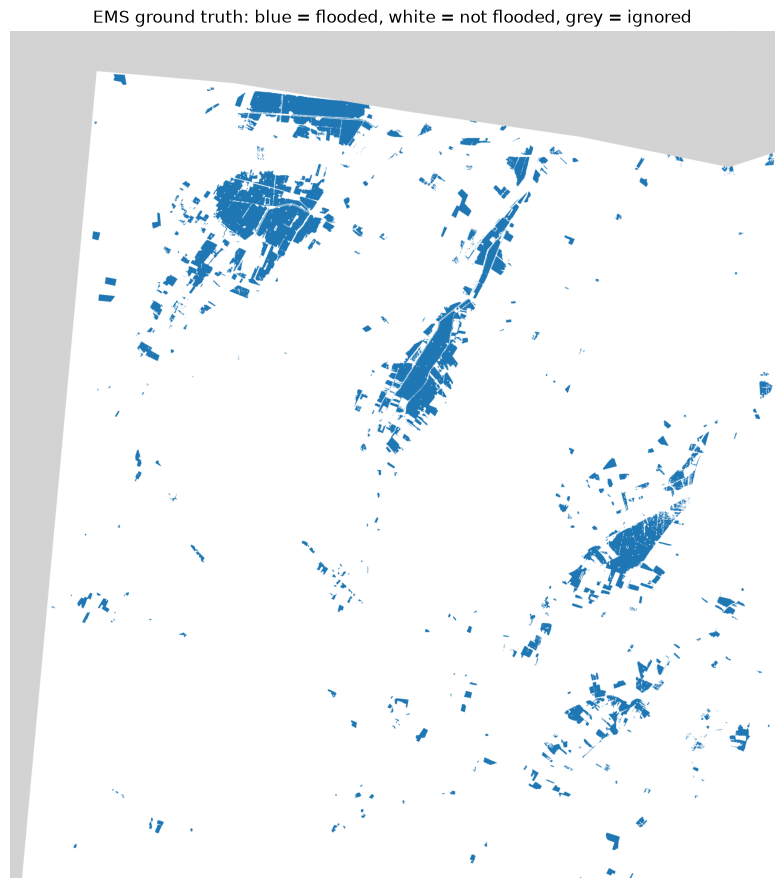

In [55]:
from matplotlib.colors import ListedColormap

# One colour per label value, in order -1, 0, 1
LABEL_CMAP = ListedColormap(["lightgrey", "white", "tab:blue"])   # ignored, not flooded, flooded

fig, ax = plt.subplots(figsize=(10, 11))
ax.imshow(labels, cmap=LABEL_CMAP, vmin=-1, vmax=1)   # ground truth on the Sentinel-1 grid
ax.set_title("EMS ground truth: blue = flooded, white = not flooded, grey = ignored")
ax.axis("off")
plt.show()

Mask and image line up pixel by pixel because both are in **UTM 32N** and we rasterized with the **transform of the Sentinel-1 image** (the rule pixel (row, col) → metres). We check it by drawing the EMS polygons on the post-event image.

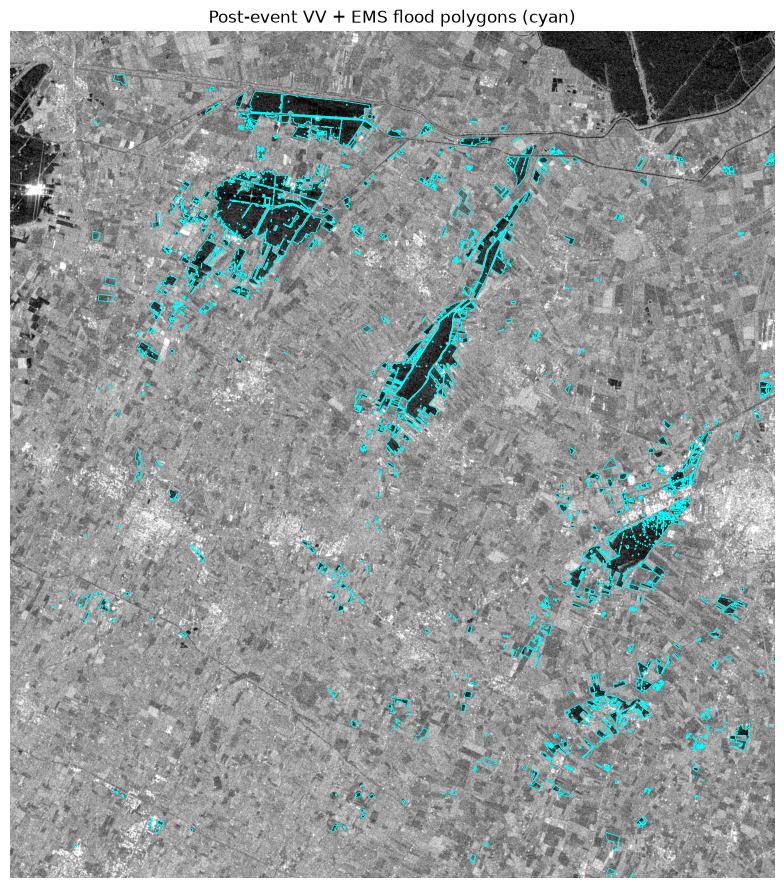

In [56]:
from rasterio.plot import plotting_extent

# Put the image in UTM metres (instead of pixel indices) so that the EMS polygons land on top of it
EXTENT = plotting_extent(post_db[0], GRID_TRANSFORM)   # (west, east, south, north) in metres

fig, ax = plt.subplots(figsize=(10, 11))
ax.imshow(post_db[0], cmap="gray", vmin=VMIN, vmax=VMAX, extent=EXTENT)   # post-event VV
flood_utm.boundary.plot(ax=ax, color="cyan", linewidth=0.6)               # EMS flood polygons (outline only)
ax.set_xlim(EXTENT[0], EXTENT[1])    # keep the view on our image (EMS polygons go beyond it)
ax.set_ylim(EXTENT[2], EXTENT[3])
ax.set_title("Post-event VV + EMS flood polygons (cyan)")
ax.axis("off")
plt.show()

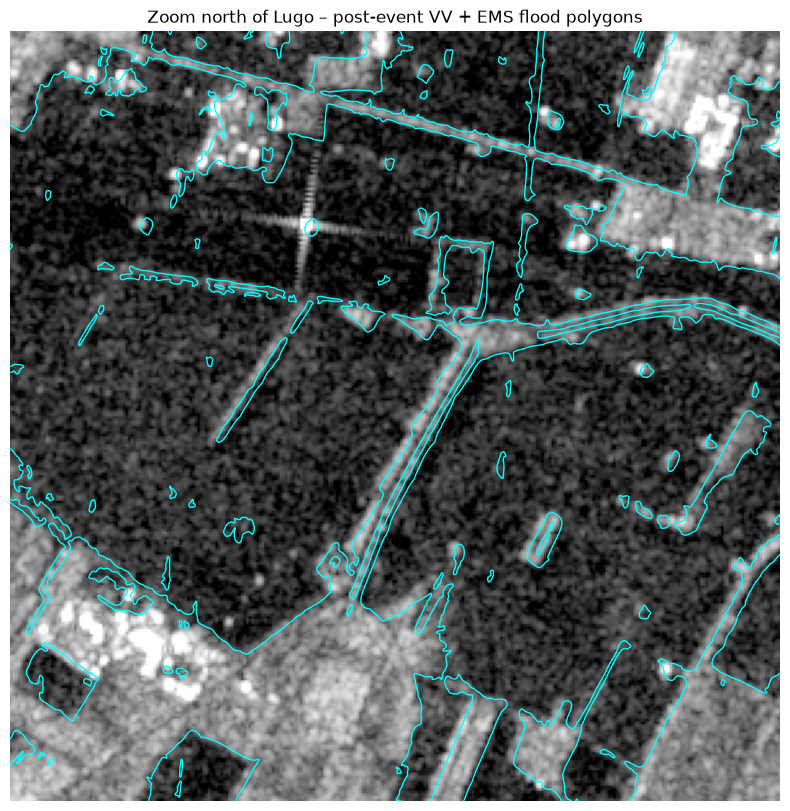

In [57]:
# Same overlay, zoomed on the 3 x 3 km window of section 3
# Corners of the window: pixel (col, row) -> UTM (x, y)
zoom_west, zoom_north = GRID_TRANSFORM * (ZOOM_COLS.start, ZOOM_ROWS.start)
zoom_east, zoom_south = GRID_TRANSFORM * (ZOOM_COLS.stop, ZOOM_ROWS.stop)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(post_db[0], cmap="gray", vmin=VMIN, vmax=VMAX, extent=EXTENT)
flood_utm.boundary.plot(ax=ax, color="cyan", linewidth=1)
ax.set_xlim(zoom_west, zoom_east)    # move the "camera" onto the window, nothing is cut
ax.set_ylim(zoom_south, zoom_north)
ax.set_title("Zoom north of Lugo – post-event VV + EMS flood polygons")
ax.axis("off")
plt.show()

The EMS outlines follow the edges of the dark fields almost pixel by pixel, while roads, embankments and villages stay outside. Our ground truth is ready: **4.5% flooded, 79.9% not flooded, 15.6% ignored**.

## 5. Otsu baseline

**Classifying** here means answering, for every pixel, *water or not?* Calm water is dark in radar, so the simplest rule is a **threshold**: pixels darker than it are water. **Otsu** picks the threshold automatically, in the valley between the two peaks of the histogram (the split that makes the two groups as compact as possible). We start with one threshold on the whole **VV post-event** image.

Global Otsu threshold: -12.19 dB
Classified as water: 29.8% of pixels (EMS: 4.5%)


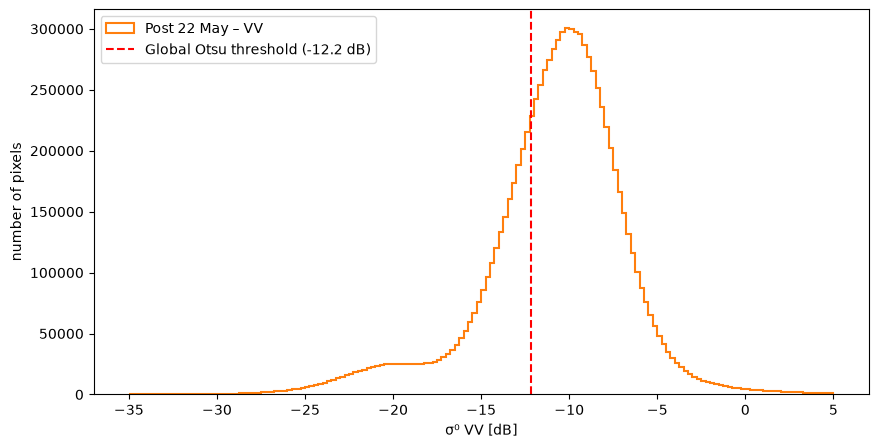

(3214, 2901)

In [58]:
from skimage.filters import threshold_otsu

post_vv = post_db[0]                              # (rows, cols) VV post-event, dB
valid_values = post_vv[np.isfinite(post_vv)]      # (n_valid,) all valid pixels in 1D, without -inf

otsu_global = threshold_otsu(valid_values)        # one number, in dB
water_global = post_vv < otsu_global              # (rows, cols) True = water

print(f"Global Otsu threshold: {otsu_global:.2f} dB")
print(f"Classified as water: {100 * water_global.mean():.1f}% of pixels (EMS: 4.5%)")

# Where did Otsu cut the histogram?
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(valid_values, bins=BINS, histtype="step", linewidth=1.5, color="tab:orange", label="Post 22 May – VV")
ax.axvline(otsu_global, color="red", linestyle="--", label=f"Global Otsu threshold ({otsu_global:.1f} dB)")
ax.set_xlabel("σ⁰ VV [dB]")
ax.set_ylabel("number of pixels")
ax.legend()
plt.show()

water_global.shape

### Dead end: global Otsu

The threshold lands at **−12.2 dB**, inside the land peak, and labels **30%** of the image as water (EMS: 4.5%). Water is too small a group, so Otsu prefers to split the land peak in two (**class imbalance**).

The usual fix, used by DLR in Copernicus GFM, is **tile-based Otsu**: we cut the image into tiles, keep only the tiles with the largest spread (water and land together) and compute Otsu on those pixels only.

kept 22 of 224 tiles
Tile-based Otsu threshold: -15.08 dB (global: -12.19 dB)
Classified as water: 11.5% of pixels (EMS: 4.5%)


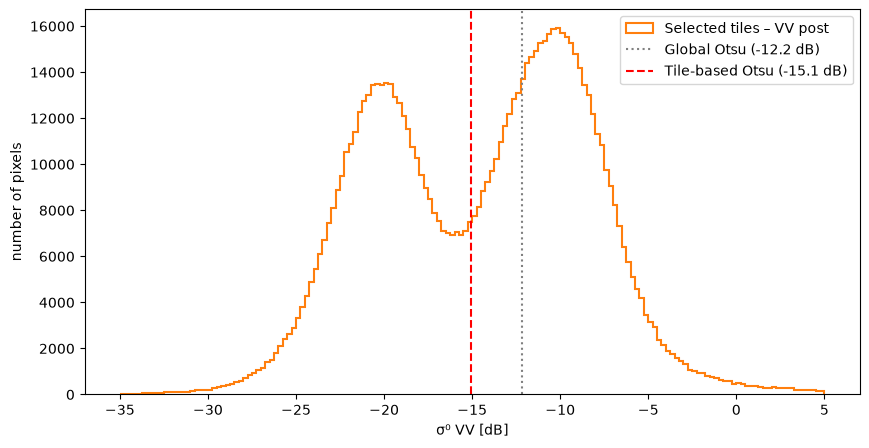

(3214, 2901)

In [59]:
TILE = 200            # pixels → tiles of 2 x 2 km
TOP_FRACTION = 0.1    # keep the 10% most contrasted tiles


def tiled_otsu(image):
    """Otsu threshold computed only on the most contrasted tiles of the image."""
    tiles = []        # valid pixels of each tile (1D arrays)
    contrast = []     # standard deviation of each tile, in dB
    for row in range(0, image.shape[0] - TILE + 1, TILE):
        for col in range(0, image.shape[1] - TILE + 1, TILE):
            tile = image[row:row + TILE, col:col + TILE]   # (200, 200)
            tile = tile[np.isfinite(tile)]                  # (n_valid,)
            tiles.append(tile)
            contrast.append(tile.std())                     # water + land in the same tile → large spread

    n_keep = int(TOP_FRACTION * len(tiles))
    best = np.argsort(contrast)[::-1][:n_keep]              # indices of the n_keep largest contrasts
    selected = np.concatenate([tiles[i] for i in best])     # (n_keep * 200 * 200,) pixels of the chosen tiles
    print(f"kept {n_keep} of {len(tiles)} tiles")
    return threshold_otsu(selected), selected


otsu_tiles, selected_values = tiled_otsu(post_vv)
water_tiles = post_vv < otsu_tiles                          # (rows, cols) True = water

print(f"Tile-based Otsu threshold: {otsu_tiles:.2f} dB (global: {otsu_global:.2f} dB)")
print(f"Classified as water: {100 * water_tiles.mean():.1f}% of pixels (EMS: 4.5%)")

# Histogram of the selected tiles only: now the water peak is big enough
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(selected_values, bins=BINS, histtype="step", linewidth=1.5, color="tab:orange", label="Selected tiles – VV post")
ax.axvline(otsu_global, color="grey", linestyle=":", label=f"Global Otsu ({otsu_global:.1f} dB)")
ax.axvline(otsu_tiles, color="red", linestyle="--", label=f"Tile-based Otsu ({otsu_tiles:.1f} dB)")
ax.set_xlabel("σ⁰ VV [dB]")
ax.set_ylabel("number of pixels")
ax.legend()
plt.show()

water_tiles.shape

On the selected tiles the histogram has **two real peaks** and the threshold (−15.1 dB) falls in the valley. But 11.5% of the image is still water: because of **speckle**, many land pixels are randomly dark.

### Speckle filter

Before thresholding we apply a **5 × 5 median filter**: each pixel takes the median of its 25 neighbours. Unlike the mean, the median removes isolated dark pixels without blurring field edges. The size is fixed **in advance**, not tuned on the EMS map, otherwise the comparison would not be fair.

kept 22 of 224 tiles
Otsu (a) threshold on filtered VV post: -15.03 dB
Classified as water: 8.6% of pixels (EMS: 4.5%)


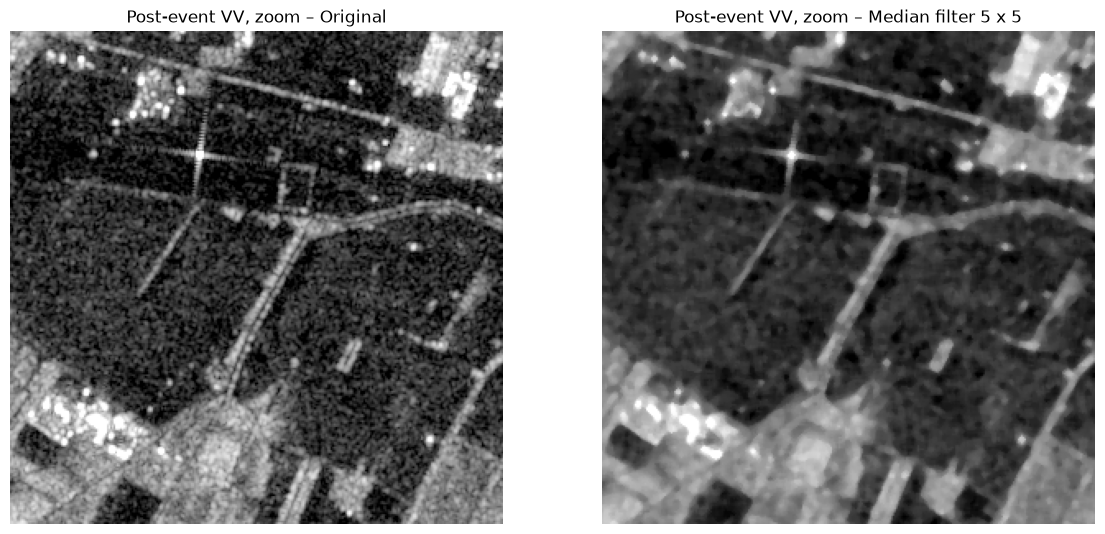

(3214, 2901)

In [60]:
from scipy.ndimage import median_filter

FILTER_SIZE = 5    # pixels → 5 x 5 window = 50 x 50 m

post_vv_filt = median_filter(post_vv, size=FILTER_SIZE)   # (rows, cols) speckle-filtered VV post, dB

otsu_post, _ = tiled_otsu(post_vv_filt)                   # we don't need the selected pixels this time
water_post = post_vv_filt < otsu_post                     # (rows, cols) Otsu (a): post-event only

print(f"Otsu (a) threshold on filtered VV post: {otsu_post:.2f} dB")
print(f"Classified as water: {100 * water_post.mean():.1f}% of pixels (EMS: 4.5%)")

# Same zoom as section 3: before and after the filter
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, title in zip(axes, [post_vv, post_vv_filt], ["Original", f"Median filter {FILTER_SIZE} x {FILTER_SIZE}"]):
    ax.imshow(image[ZOOM_ROWS, ZOOM_COLS], cmap="gray", vmin=VMIN, vmax=VMAX)
    ax.set_title(f"Post-event VV, zoom – {title}")
    ax.axis("off")
plt.show()

water_post.shape

### Otsu (b): change detection

With the filter, water drops to **8.6%**. Otsu (a) only asks *is this pixel dark now?*, so it also counts water that was **already there** before the flood. Change detection asks *did this pixel get darker?*: we threshold the **difference post − pre** (in dB), with the same filter and the same tile-based Otsu.

Four example pixels (VV, dB):

| pixel | pre | post | post − pre | Otsu (a): post < −15 | Otsu (b): post − pre < −1.9 |
|---|---|---|---|---|---|
| flooded field | −9 | −20 | −11 | water ✅ | water ✅ |
| lake (already there) | −21 | −21 | 0 | water ❌ | not water ✅ |
| dry field | −11 | −8 | +3 | not water ✅ | not water ✅ |
| ploughed field | −7 | −10 | −3 | not water ✅ | water ❌ |

The code is the same for both, only the input changes: `tiled_otsu(post_vv_filt)` for (a), `tiled_otsu(diff_vv)` for (b).

kept 22 of 224 tiles
Otsu (b) threshold on post − pre: -1.92 dB
Classified as water: 6.4% of pixels (Otsu (a): 8.6%, EMS: 4.5%)


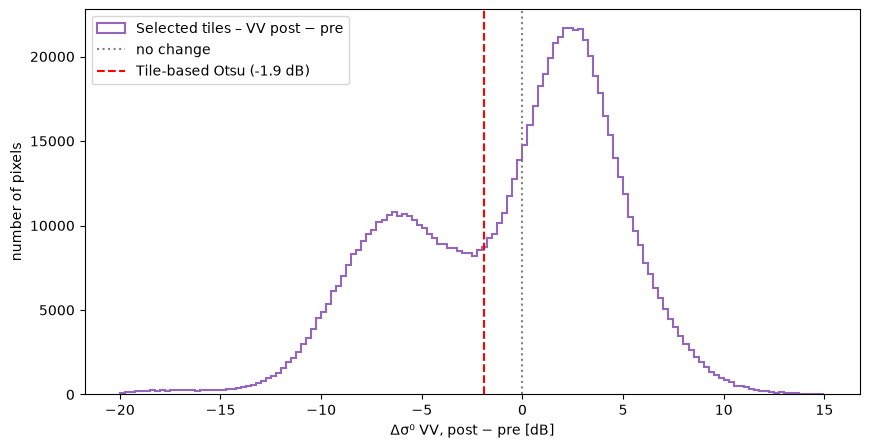

(3214, 2901)

In [61]:
pre_vv_filt = median_filter(pre_db[0], size=FILTER_SIZE)   # (rows, cols) same filter on VV pre, dB
diff_vv = post_vv_filt - pre_vv_filt                       # (rows, cols) change in dB: new water → strongly negative

otsu_change, selected_diff = tiled_otsu(diff_vv)
water_change = diff_vv < otsu_change                       # (rows, cols) Otsu (b): got darker than the threshold

print(f"Otsu (b) threshold on post − pre: {otsu_change:.2f} dB")
print(f"Classified as water: {100 * water_change.mean():.1f}% of pixels (Otsu (a): {100 * water_post.mean():.1f}%, EMS: 4.5%)")

# Histogram of the difference on the selected tiles
DIFF_BINS = np.linspace(-20, 15, 141)   # dB, bins 0.25 dB wide

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(selected_diff, bins=DIFF_BINS, histtype="step", linewidth=1.5, color="tab:purple", label="Selected tiles – VV post − pre")
ax.axvline(0, color="grey", linestyle=":", label="no change")
ax.axvline(otsu_change, color="red", linestyle="--", label=f"Tile-based Otsu ({otsu_change:.1f} dB)")
ax.set_xlabel("Δσ⁰ VV, post − pre [dB]")
ax.set_ylabel("number of pixels")
ax.legend()
plt.show()

water_change.shape

The histogram of the difference has **two peaks**: unchanged land around **+2.5 dB** and new water around **−6.5 dB**, with the threshold (**−1.9 dB**) in the valley. Water drops to **6.4%** of the image.

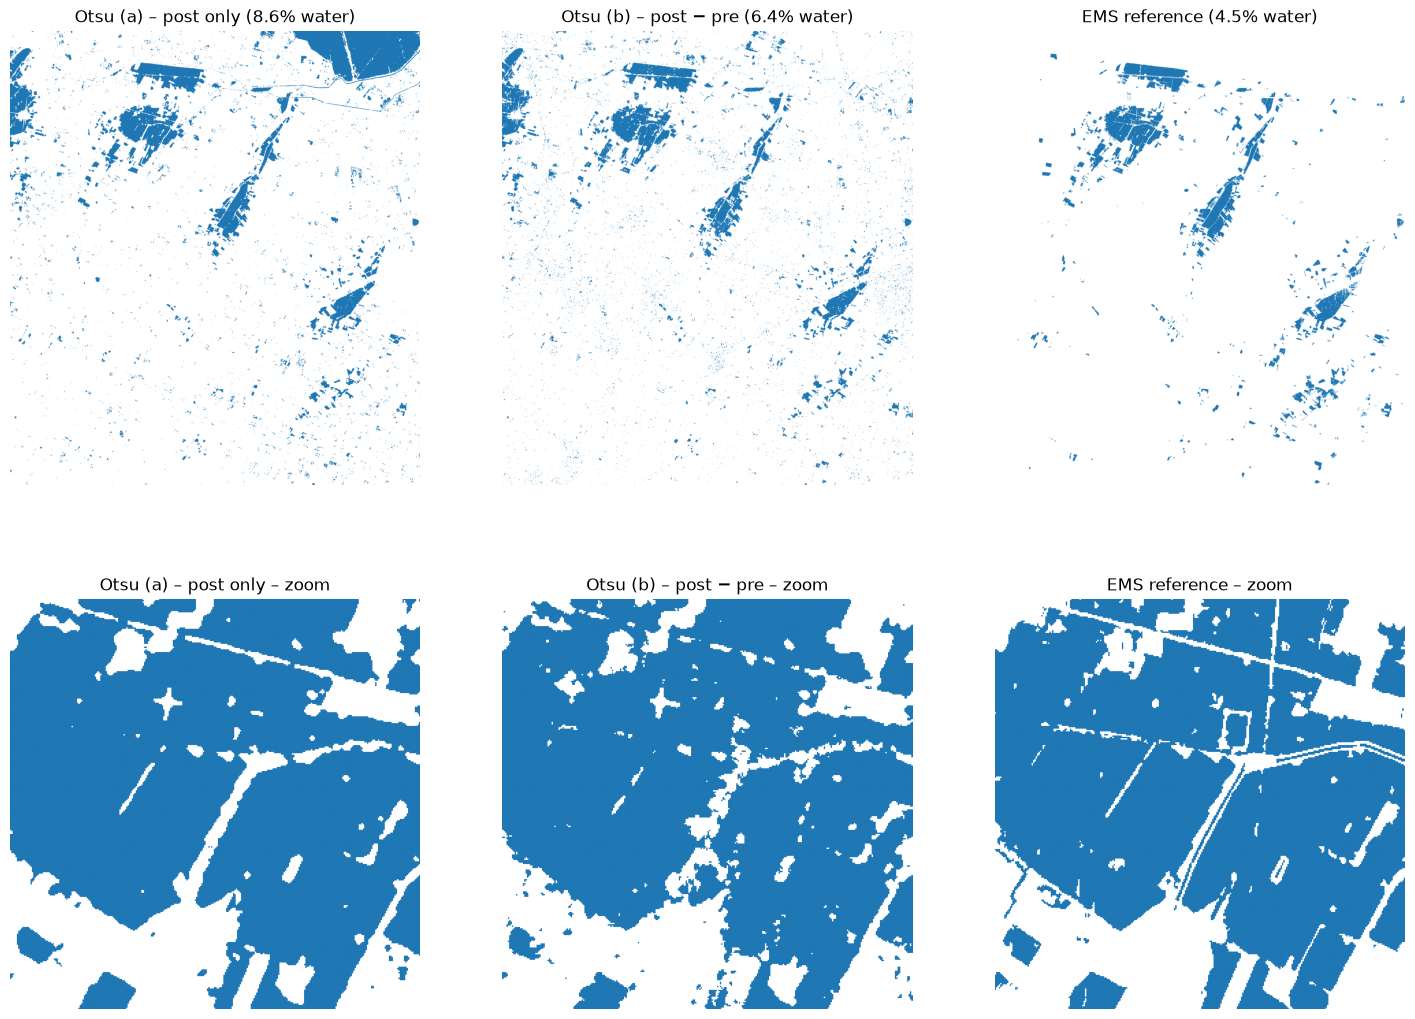

((3214, 2901), (3214, 2901))

In [62]:
# Otsu (a), Otsu (b) and EMS side by side: whole image (top) and zoom north of Lugo (bottom)
WATER_CMAP = ListedColormap(["white", "tab:blue"])   # 0 = no water, 1 = water

maps = [water_post, water_change, labels == 1]       # 3 x (rows, cols), True = water
titles = ["Otsu (a) – post only", "Otsu (b) – post − pre", "EMS reference"]

fig, axes = plt.subplots(2, 3, figsize=(18, 13))
for col, (water, title) in enumerate(zip(maps, titles)):
    axes[0, col].imshow(water, cmap=WATER_CMAP, vmin=0, vmax=1)
    axes[0, col].set_title(f"{title} ({100 * water.mean():.1f}% water)")
    axes[1, col].imshow(water[ZOOM_ROWS, ZOOM_COLS], cmap=WATER_CMAP, vmin=0, vmax=1)
    axes[1, col].set_title(f"{title} – zoom")
for ax in axes.ravel():
    ax.axis("off")
plt.show()

water_post.shape, water_change.shape

Both methods find the **main flooded areas** of EMS:
- **Otsu (a)** also marks the **permanent water** (wetlands top right, river, canals); **Otsu (b)** removes it.
- **Otsu (b)** has more **scattered dots**: the speckle of two images adds up, and some fields changed for other reasons (ploughing, harvest).
- Neither sees the **roads and embankments** inside the flood: the 5 × 5 filter erases them.

In the EMS panel, white also includes the **ignored** areas (left strip, top right), which do not count in the metrics.

## 6. Metrics

We compare each water map with the EMS labels **pixel by pixel**, only where the label is not −1. Every valid pixel falls in one of four boxes (**confusion matrix**):

| | EMS: water | EMS: not water |
|---|---|---|
| **predicted water** | TP (true positive) | FP (false alarm) |
| **predicted not water** | FN (missed water) | TN (true negative) |

From these counts:
- **precision** = TP / (TP + FP): of the pixels we call water, how many really are
- **recall** = TP / (TP + FN): of the real water, how much we find
- **F1** = 2 · precision · recall / (precision + recall): one number that balances the two
- **IoU** = TP / (TP + FP + FN): our water and the EMS water, overlap divided by union. It is our **main metric**, as in the Sen1Floods11 paper.

We don't use accuracy: with 95% dry land, a map with no water at all would already be 95% accurate.

In [63]:
def confusion_counts(water, labels):
    """TP, FP, FN, TN of a water map (True = water) against labels (1, 0, -1 = ignored)."""
    valid = labels != -1          # True = pixel counts in the metrics
    pred = water[valid]           # (n_valid,) True = we say water
    true = labels[valid] == 1     # (n_valid,) True = EMS says water
    tp = np.sum(pred & true)      # water for both
    fp = np.sum(pred & ~true)     # we say water, EMS says no → false alarm
    fn = np.sum(~pred & true)     # EMS says water, we say no → missed water
    tn = np.sum(~pred & ~true)    # not water for both
    return tp, fp, fn, tn


def flood_metrics(water, labels):
    """IoU, precision, recall and F1 of a water map against the labels."""
    tp, fp, fn, tn = confusion_counts(water, labels)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    return {
        "IoU": tp / (tp + fp + fn),
        "precision": precision,
        "recall": recall,
        "F1": 2 * precision * recall / (precision + recall),
    }


# Toy check on 6 pixels, small enough to count by hand
toy_labels = np.array([1, 1, 0, 0, 0, -1])                    # EMS: water, water, dry, dry, dry, ignored
toy_water = np.array([True, False, True, False, False, True])  # our map
# pixel 0 → TP, pixel 1 → FN, pixel 2 → FP, pixels 3-4 → TN, pixel 5 → ignored
# ⇒ IoU = 1 / (1 + 1 + 1) = 0.33, precision = 1 / 2, recall = 1 / 2, F1 = 0.5

print("TP, FP, FN, TN:", confusion_counts(toy_water, toy_labels))
flood_metrics(toy_water, toy_labels)

TP, FP, FN, TN: (np.int64(1), np.int64(1), np.int64(1), np.int64(2))


{'IoU': np.float64(0.3333333333333333),
 'precision': np.float64(0.5),
 'recall': np.float64(0.5),
 'F1': np.float64(0.5)}

In [64]:
# Results table: one row per method, metrics against EMS (ignored pixels excluded)
import pandas as pd   # installed together with geopandas

methods = {
    "Otsu (a) – post only": water_post,      # (rows, cols) True = water
    "Otsu (b) – post − pre": water_change,   # (rows, cols) True = water
}

rows = []
for name, water in methods.items():
    tp, fp, fn, tn = confusion_counts(water, labels)
    row = {"method": name, "TP": tp, "FP": fp, "FN": fn, "TN": tn}
    row.update(flood_metrics(water, labels))   # adds IoU, precision, recall, F1
    rows.append(row)

results = pd.DataFrame(rows).set_index("method")   # (2 methods, 8 columns)
results.round(3)

,TP,FP,FN,TN,IoU,precision,recall,F1
method,,,,,,,,
Otsu (a) – post only,336336,140189,86124,7305406,0.598,0.706,0.796,0.748
Otsu (b) – post − pre,319489,159581,102971,7286014,0.549,0.667,0.756,0.709


**Otsu (a) beats Otsu (b)**: IoU **0.60** vs **0.55**, even though (b) looked cleaner on the map.
- The permanent water that (b) removes lies mostly in the **ignored** area (Ravenna wetlands) → it barely counts.
- (b) has **more false alarms** (160k vs 140k): speckle of two images and fields that changed for other reasons.
- (b) also **misses more water** (103k vs 86k): probably fields that were already dark on 28 April (wet bare soil) and don't get much darker.

Recall is about **0.8** for both: most of the EMS water is found, and the main error is **false alarms**.

## 7. Sen1Floods11

Otsu needs no examples. The U-Net instead **learns from examples**: radar images where someone has already marked the water. We can't use the EMS map for this, because it is our **test**: the U-Net must never see Emilia-Romagna during training.

So we use **Sen1Floods11**: Sentinel-1 images (VV, VH in dB, like ours) of **11 floods around the world**, cut into squares of 512 × 512 pixels (**chips**), with the water drawn by hand (1 = water, 0 = not water, −1 = no data). The dataset comes already split into **train / valid / test**, and we keep that split.

In [65]:
import requests

S1F_URL = "https://storage.googleapis.com/sen1floods11/v1.1"   # public bucket, no login needed
S1F_DIR = DATA_DIR / "sen1floods11"
SPLITS = ["train", "valid", "test"]

for folder in [S1F_DIR / "S1Hand", S1F_DIR / "LabelHand"]:   # images and labels, as in the bucket
    folder.mkdir(parents=True, exist_ok=True)


def download_file(url, output_file):
    """Download one file over HTTPS, skip it if we already have it."""
    if output_file.exists():
        return
    response = requests.get(url, timeout=60)
    response.raise_for_status()               # stop with an error if the server says 404 etc.
    output_file.write_bytes(response.content)


# Official split: one CSV per split, each line = "<image file>,<label file>"
split_files = {}
for split in SPLITS:
    csv_file = S1F_DIR / f"flood_{split}_data.csv"
    download_file(f"{S1F_URL}/splits/flood_handlabeled/flood_{split}_data.csv", csv_file)
    lines = csv_file.read_text().split()                    # one string per line
    split_files[split] = [line.split(",") for line in lines]   # list of [image name, label name]

print({split: len(pairs) for split, pairs in split_files.items()})
split_files["train"][0]

{'train': 252, 'valid': 89, 'test': 90}


['Ghana_103272_S1Hand.tif', 'Ghana_103272_LabelHand.tif']

In [66]:
# Download all chips of the three splits: ~431 images of ~1.8 MB each (~780 MB) + small labels
# Already-downloaded files are skipped → if it stops halfway, just run the cell again
HAND_URL = f"{S1F_URL}/data/flood_events/HandLabeled"

for split in SPLITS:
    for i, (image_name, label_name) in enumerate(split_files[split]):
        download_file(f"{HAND_URL}/S1Hand/{image_name}", S1F_DIR / "S1Hand" / image_name)
        download_file(f"{HAND_URL}/LabelHand/{label_name}", S1F_DIR / "LabelHand" / label_name)
        if (i + 1) % 50 == 0:
            print(f"{split}: {i + 1}/{len(split_files[split])}")
    print(f"{split}: done")

len(list((S1F_DIR / "S1Hand").glob("*.tif"))), len(list((S1F_DIR / "LabelHand").glob("*.tif")))   # (431, 431)

train: 50/252
train: 100/252
train: 150/252
train: 200/252
train: 250/252
train: done
valid: 50/89
valid: done
test: 50/90
test: done


(431, 431)

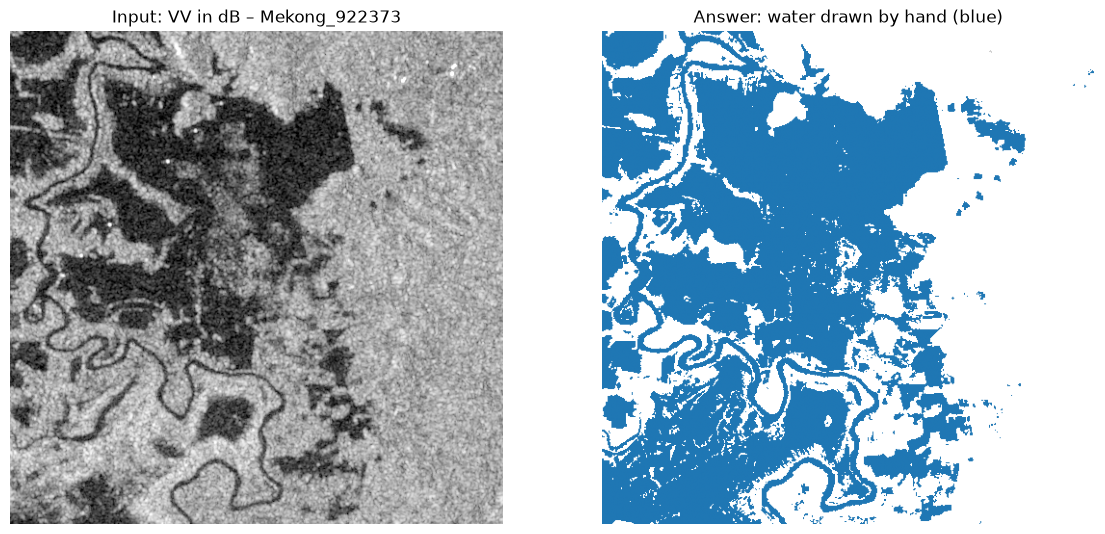

((2, 512, 512), (512, 512))

In [67]:
# One training example: the radar image (what the U-Net sees) and the water drawn by hand (the answer it must learn)
EXAMPLE = "Mekong_922373"   # a train chip with flooded fields and a river

with rasterio.open(S1F_DIR / "S1Hand" / f"{EXAMPLE}_S1Hand.tif") as src:
    chip = src.read()                # (2, 512, 512) VV, VH in dB
with rasterio.open(S1F_DIR / "LabelHand" / f"{EXAMPLE}_LabelHand.tif") as src:
    chip_label = src.read(1)         # (512, 512) 1 = water, 0 = not water, -1 = no data

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(chip[0], cmap="gray", vmin=VMIN, vmax=VMAX)    # same grey scale as our Emilia-Romagna images
axes[0].set_title(f"Input: VV in dB – {EXAMPLE}")
axes[1].imshow(chip_label, cmap=LABEL_CMAP, vmin=-1, vmax=1)  # same colours as our EMS mask
axes[1].set_title("Answer: water drawn by hand (blue)")
for ax in axes:
    ax.axis("off")
plt.show()

chip.shape, chip_label.shape

In [68]:
def load_split(split):
    """All chips of one split: images (n, 2, 512, 512) in dB and labels (n, 512, 512) with 1, 0, -1."""
    images, labels_list = [], []
    for image_name, label_name in split_files[split]:
        with rasterio.open(S1F_DIR / "S1Hand" / image_name) as src:
            images.append(src.read())            # (2, 512, 512) VV, VH
        with rasterio.open(S1F_DIR / "LabelHand" / label_name) as src:
            labels_list.append(src.read(1))      # (512, 512)
    X = np.stack(images).astype(np.float32)      # (n, 2, 512, 512)
    y = np.stack(labels_list).astype(np.int8)    # (n, 512, 512)

    # Some chips have pixels with no radar value (NaN) → we can't learn anything there → label -1 (ignored)
    no_data = np.isnan(X).any(axis=1)            # (n, 512, 512) True if VV or VH is missing
    y[no_data] = -1
    return X, y


X_train, y_train = load_split("train")
X_valid, y_valid = load_split("valid")
X_test, y_test = load_split("test")

X_train.shape, y_train.shape, X_valid.shape, X_test.shape

((252, 2, 512, 512), (252, 512, 512), (89, 2, 512, 512), (90, 2, 512, 512))

### Normalization

Values in dB go from about −30 to 0, and VH is darker than VV. A neural network learns better when every input band is centred on **0** with spread **1**, so for each band we subtract its **mean** and divide by its **standard deviation**.

We compute mean and standard deviation on the **train** chips only, and then use the **same numbers** for valid, test and Emilia-Romagna. The U-Net must not get any information from the data we test it on.

In [69]:
# Mean and standard deviation of each band, on the train chips only (NaN pixels skipped)
BAND_MEAN = np.nanmean(X_train, axis=(0, 2, 3))   # (2,) one number per band: VV, VH
BAND_STD = np.nanstd(X_train, axis=(0, 2, 3))     # (2,)
print("mean [dB] VV, VH:", BAND_MEAN.round(2), "| std [dB]:", BAND_STD.round(2))


def normalize(X):
    """dB → centred on 0 with spread 1, band by band, with the train statistics. NaN → 0 (= the mean)."""
    X = (X - BAND_MEAN[None, :, None, None]) / BAND_STD[None, :, None, None]   # (n, 2, rows, cols)
    return np.nan_to_num(X, nan=0.0)              # these pixels are label -1 anyway, the value doesn't matter


X_train_n = normalize(X_train)   # (252, 2, 512, 512)
X_valid_n = normalize(X_valid)   # (89, 2, 512, 512)
X_test_n = normalize(X_test)     # (90, 2, 512, 512)

print("train after normalization, mean VV, VH:", X_train_n.mean(axis=(0, 2, 3)).round(2),
      "| std:", X_train_n.std(axis=(0, 2, 3)).round(2))
X_train_n.shape

mean [dB] VV, VH: [-10.39 -17.24] | std [dB]: [4.04 4.75]
train after normalization, mean VV, VH: [-0. -0.] | std: [0.99 0.99]


(252, 2, 512, 512)

In [70]:
# Cut every 512 x 512 chip into 4 patches of 256 x 256 → lighter for training on CPU
PATCH = 256


def to_patches(X, y):
    """4 patches per chip: X (n, 2, 512, 512) → (m, 2, 256, 256), y (n, 512, 512) → (m, 256, 256)."""
    X_patches, y_patches = [], []
    for i in range(len(X)):                              # every chip
        for row in range(0, X.shape[2], PATCH):          # row = 0, 256
            for col in range(0, X.shape[3], PATCH):      # col = 0, 256
                y_patch = y[i, row:row + PATCH, col:col + PATCH]          # (256, 256)
                if np.all(y_patch == -1):                # nothing to learn from this patch → skip it
                    continue
                X_patches.append(X[i, :, row:row + PATCH, col:col + PATCH])   # (2, 256, 256)
                y_patches.append(y_patch)
    return np.stack(X_patches), np.stack(y_patches)


Xp_train, yp_train = to_patches(X_train_n, y_train)
Xp_valid, yp_valid = to_patches(X_valid_n, y_valid)
Xp_test, yp_test = to_patches(X_test_n, y_test)

for name, y in [("train", yp_train), ("valid", yp_valid), ("test", yp_test)]:
    print(f"{name}: {len(y)} patches, water = {100 * np.mean(y[y != -1] == 1):.1f}% of the valid pixels")

Xp_train.shape, yp_train.shape

train: 984 patches, water = 9.5% of the valid pixels
valid: 342 patches, water = 11.0% of the valid pixels
test: 348 patches, water = 12.3% of the valid pixels


((984, 2, 256, 256), (984, 256, 256))

The training data are ready: **984 train**, 342 valid and 348 test patches of 256 × 256. Water is only about **10%** of the pixels, so, as for Otsu, the classes are **unbalanced**: we will take this into account in the loss.

## 8. U-Net

The U-Net takes a patch (VV, VH) and gives, for every pixel, a number that says **how likely it is to be water**. It has the shape of a **U**:
- **going down**, it looks for patterns in the image and halves its size at every step: it understands better *what* is there, but loses *where* exactly;
- **going up**, it brings the image back to full size, to give one answer per pixel;
- **skip connections** carry the fine details from the left side to the right side, so that the edges of the water stay sharp.

The basic tool is the **convolution**: a small 3 × 3 window that slides over the image, like our median filter, but with weights that the network **learns** from the examples.

In [71]:
import torch.nn as nn


def conv_block(in_channels, out_channels):
    """Basic step of the U-Net: two 3 x 3 convolutions, each followed by batch normalization and ReLU.
    The image size does not change, only the number of channels."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),   # out_channels learned 3 x 3 filters
        nn.BatchNorm2d(out_channels),                                     # keeps values centred on 0, spread 1
        nn.ReLU(),                                                        # negative values → 0
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
    )


# Try it on one training patch
block = conv_block(2, 16)                    # 2 input bands (VV, VH) → 16 feature maps
patch = torch.from_numpy(Xp_train[:1])       # (1, 2, 256, 256) numpy → torch tensor, batch of 1 patch
out = block(patch)

patch.shape, out.shape                       # (1, 2, 256, 256) → (1, 16, 256, 256)

(torch.Size([1, 2, 256, 256]), torch.Size([1, 16, 256, 256]))

We keep the U-Net **small**: 3 steps down, from 16 to 128 channels. The original U-Net (Ronneberger et al., 2015) has 4 steps and goes from 64 to 1024 channels, about 31 million weights: too slow without a GPU, and too many for our ~1000 training patches.

In [72]:
class UNet(nn.Module):
    """Small U-Net: patch (batch, 2, 256, 256) → water score (batch, 1, 256, 256)."""

    def __init__(self, in_channels=2, base=16):
        super().__init__()
        # Going down: conv_block, then halve the size with max pooling
        self.down1 = conv_block(in_channels, base)       # 256 x 256, 16 channels
        self.down2 = conv_block(base, base * 2)          # 128 x 128, 32 channels
        self.down3 = conv_block(base * 2, base * 4)      #  64 x 64,  64 channels
        self.bottom = conv_block(base * 4, base * 8)     #  32 x 32, 128 channels (bottom of the U)
        self.pool = nn.MaxPool2d(2)                      # keeps the largest of every 2 x 2 pixels → half size

        # Going up: double the size, glue the skip connection, conv_block
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, kernel_size=2, stride=2)   # 32 → 64
        self.dec3 = conv_block(base * 8, base * 4)       # 64 (from below) + 64 (skip) channels in
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)   # 64 → 128
        self.dec2 = conv_block(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)       # 128 → 256
        self.dec1 = conv_block(base * 2, base)

        self.out = nn.Conv2d(base, 1, kernel_size=1)     # 16 channels → 1 number per pixel

    def forward(self, x):                                       # x: (batch, 2, 256, 256)
        d1 = self.down1(x)                                      # (batch, 16, 256, 256)
        d2 = self.down2(self.pool(d1))                          # (batch, 32, 128, 128)
        d3 = self.down3(self.pool(d2))                          # (batch, 64, 64, 64)
        b = self.bottom(self.pool(d3))                          # (batch, 128, 32, 32)

        u3 = self.dec3(torch.cat([self.up3(b), d3], dim=1))     # (batch, 64, 64, 64)    skip from d3
        u2 = self.dec2(torch.cat([self.up2(u3), d2], dim=1))    # (batch, 32, 128, 128)  skip from d2
        u1 = self.dec1(torch.cat([self.up1(u2), d1], dim=1))    # (batch, 16, 256, 256)  skip from d1
        return self.out(u1)                                     # (batch, 1, 256, 256) score: > 0 water, < 0 not water


model = UNet()
n_weights = sum(p.numel() for p in model.parameters())   # how many numbers the network has to learn
print(f"U-Net weights: {n_weights:,}")

scores = model(torch.from_numpy(Xp_train[:4]))   # try it on 4 training patches (still random weights)
scores.shape                                     # (4, 1, 256, 256)

U-Net weights: 483,297


torch.Size([4, 1, 256, 256])

## 9. Training

Training repeats the same loop many times: we give the U-Net a small group of patches (a **batch**), it answers, the **loss** measures with one number how wrong it is, and the **optimizer** changes all the weights a little so that it is less wrong next time. One pass over all the training patches is an **epoch**. After every epoch we compute the IoU on the **valid** patches and keep the weights of the best epoch.

### Loss

The score of every pixel becomes a probability of water with the **sigmoid**, and the **binary cross-entropy (BCE)** gives a big penalty when the network is confident and wrong. We change it in two ways:
- pixels with label **−1** don't count;
- water is only ~10% of the pixels, so an error on water counts as much as the ratio **land / water** (`pos_weight`). Otherwise the network could just say "land" everywhere.

We prefer this to the **Dice loss** (which measures the overlap directly, like IoU) because it is simpler and stable on the many patches with no water. The price: the network may call water a bit too often.

In [73]:
import torch.nn.functional as F

# How much more an error on water counts: land pixels / water pixels, on the train patches only
POS_WEIGHT = np.sum(yp_train == 0) / np.sum(yp_train == 1)
print(f"pos_weight = {POS_WEIGHT:.1f}  (patches without water: {np.sum(np.all(yp_train != 1, axis=(1, 2)))} of {len(yp_train)})")


def masked_bce(scores, labels, pos_weight):
    """BCE on the valid pixels only (label -1 ignored), water errors weighted pos_weight times.
    scores: (batch, 1, 256, 256) output of the U-Net, labels: (batch, 256, 256) with 1, 0, -1."""
    valid = labels != -1                              # (batch, 256, 256) True = pixel counts
    return F.binary_cross_entropy_with_logits(
        scores[:, 0][valid],                          # (n_valid,) scores of the valid pixels
        labels[valid].float(),                        # (n_valid,) 1.0 = water, 0.0 = not water
        pos_weight=torch.tensor(pos_weight, dtype=torch.float32),
    )


# Try it on 4 patches with the untrained U-Net (random weights → the loss is high)
scores = model(torch.from_numpy(Xp_train[:4]))       # (4, 1, 256, 256)
loss = masked_bce(scores, torch.from_numpy(yp_train[:4]), POS_WEIGHT)
loss.item()                                           # one number: how wrong the network is

pos_weight = 9.5  (patches without water: 225 of 984)


0.7559547424316406

In [74]:
import time

BATCH_SIZE = 8           # patches per step
LEARNING_RATE = 1e-3     # how big each correction of the weights is (usual value for Adam)


def train_step(model, optimizer, X_batch, y_batch, pos_weight):
    """One turn of the loop: the U-Net answers, the loss measures the error, the optimizer corrects the weights."""
    model.train()                       # training mode (batch normalization uses the statistics of this batch)
    optimizer.zero_grad()               # forget the corrections computed at the previous step
    scores = model(X_batch)             # (batch, 1, 256, 256)
    loss = masked_bce(scores, y_batch, pos_weight)
    loss.backward()                     # for every weight: in which direction does it lower the loss?
    optimizer.step()                    # move every weight a little in that direction
    return loss.item()


# Speed test: 10 batches → how long would one epoch take on our CPU?
torch.manual_seed(SEED)
model = UNet()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

start = time.time()
for i in range(10):
    X_batch = torch.from_numpy(Xp_train[i * BATCH_SIZE:(i + 1) * BATCH_SIZE])   # (8, 2, 256, 256)
    y_batch = torch.from_numpy(yp_train[i * BATCH_SIZE:(i + 1) * BATCH_SIZE])   # (8, 256, 256)
    print(f"batch {i}: loss {train_step(model, optimizer, X_batch, y_batch, POS_WEIGHT):.3f}")

seconds_per_batch = (time.time() - start) / 10
n_batches = int(np.ceil(len(Xp_train) / BATCH_SIZE))   # 984 / 8 → 123 batches per epoch
print(f"{seconds_per_batch:.1f} s per batch → about {seconds_per_batch * n_batches / 60:.1f} min per epoch ({n_batches} batches)")

batch 0: loss 0.672
batch 1: loss 0.711
batch 2: loss 0.658
batch 3: loss 0.600
batch 4: loss 0.604
batch 5: loss 1.435
batch 6: loss 0.582
batch 7: loss 0.622
batch 8: loss 0.596
batch 9: loss 0.575
1.3 s per batch → about 2.6 min per epoch (123 batches)


One epoch takes about **4 minutes** on our CPU, so we train here: **15 epochs ≈ 1 hour**. Colab would be faster, but we would have to upload the data and set everything up again.

At every epoch the patches are **shuffled**, so each batch mixes different floods. After every epoch we compute the IoU on the **valid** patches, and we save the weights only when it improves: the **best epoch** is chosen on valid, never on test or Emilia-Romagna.

In [75]:
EPOCHS = 15


def predict(model, X):
    """Water map (True = water) for many normalized patches X (n, 2, 256, 256), in batches, without training."""
    model.eval()                                  # evaluation mode (batch normalization uses what it learned)
    water = []
    with torch.no_grad():                         # no corrections → faster, less memory
        for i in range(0, len(X), BATCH_SIZE):
            scores = model(torch.from_numpy(X[i:i + BATCH_SIZE]))   # (batch, 1, 256, 256)
            water.append(scores[:, 0].numpy() > 0)                  # score > 0 ⇔ probability of water > 50%
    return np.concatenate(water)                  # (n, 256, 256)


def train_unet(pos_weight, name):
    """Train a new U-Net with this pos_weight and keep the epoch with the best valid IoU.
    Saved in models/unet_<name>.pt and models/history_<name>.csv: if they exist, we load them instead of training again."""
    model_file = MODELS_DIR / f"unet_{name}.pt"
    history_file = MODELS_DIR / f"history_{name}.csv"
    torch.manual_seed(SEED)                       # same random starting weights for every run → fair comparison
    model = UNet()

    if model_file.exists():                       # already trained → don't wait another hour at every Run All
        print("already trained:", model_file)
        model.load_state_dict(torch.load(model_file))
        return model, pd.read_csv(history_file)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    rng = np.random.default_rng(SEED)             # random generator for the shuffling
    rows = []
    best_iou = 0
    for epoch in range(1, EPOCHS + 1):
        start = time.time()

        # 1) Train: all the patches once, in a new random order
        order = rng.permutation(len(Xp_train))    # (984,) shuffled patch indices
        losses = []
        for i in range(0, len(order), BATCH_SIZE):
            batch = order[i:i + BATCH_SIZE]       # indices of the 8 patches of this step
            losses.append(train_step(model, optimizer, torch.from_numpy(Xp_train[batch]),
                                     torch.from_numpy(yp_train[batch]), pos_weight))

        # 2) Check on valid: same metrics we used for Otsu
        row = {"epoch": epoch, "train loss": np.mean(losses)}
        row.update(flood_metrics(predict(model, Xp_valid), yp_valid))
        rows.append(row)

        # 3) Keep the best epoch
        saved = ""
        if row["IoU"] > best_iou:
            best_iou = row["IoU"]
            torch.save(model.state_dict(), model_file)
            saved = "  ← best so far, saved"

        print(f"epoch {epoch:2d}/{EPOCHS} | train loss {row['train loss']:.3f} | valid IoU {row['IoU']:.3f} "
              f"(precision {row['precision']:.2f}, recall {row['recall']:.2f}) | {(time.time() - start) / 60:.1f} min{saved}")

    model.load_state_dict(torch.load(model_file))  # go back to the weights of the best epoch
    history = pd.DataFrame(rows)
    history.to_csv(history_file, index=False)
    return model, history


# First try: pos_weight = land / water
model_pw9, history_pw9 = train_unet(POS_WEIGHT, "pw9.5")
history_pw9.round(3)

already trained: models\unet_pw9.5.pt


,epoch,train loss,IoU,precision,recall,F1
0,1,0.794,0.310,0.316,0.945,0.473
1,2,0.660,0.581,0.651,0.845,0.735
2,3,0.617,0.555,0.606,0.868,0.714
3,4,0.599,0.367,0.374,0.957,0.537
4,5,0.608,0.366,0.372,0.955,0.536
5,6,0.612,0.466,0.484,0.925,0.635
6,7,0.581,0.445,0.458,0.941,0.616
7,8,0.572,0.534,0.562,0.913,0.696
8,9,0.609,0.540,0.573,0.905,0.701
9,10,0.565,0.357,0.365,0.944,0.526


### Dead end: pos_weight 9.5

With the full ratio land / water, an error on water costs 9.5 times more than an error on land, so the U-Net calls "water" almost everywhere it is unsure: **recall 0.85–0.96**, but **precision 0.32–0.65**. The valid IoU jumps between **0.31 and 0.58** from one epoch to the next, because many land pixels sit right at the 50% boundary.

We train again with **pos_weight = 3** (about √9.5): water still counts more than land, but less. We change only this, and we choose by looking at the **valid** patches, never at test or Emilia-Romagna.

In [76]:
# Second try: pos_weight = 3 → fewer false alarms? (~1 hour)
model_pw3, history_pw3 = train_unet(3.0, "pw3")
history_pw3.round(3)

already trained: models\unet_pw3.pt


,epoch,train loss,IoU,precision,recall,F1
0,1,0.546,0.602,0.770,0.735,0.752
1,2,0.398,0.084,0.791,0.085,0.154
2,3,0.350,0.615,0.777,0.747,0.762
3,4,0.328,0.455,0.492,0.861,0.626
4,5,0.325,0.591,0.673,0.829,0.743
5,6,0.312,0.621,0.764,0.768,0.766
6,7,0.291,0.522,0.552,0.905,0.686
7,8,0.297,0.610,0.813,0.709,0.757
8,9,0.290,0.635,0.799,0.756,0.777
9,10,0.286,0.488,0.529,0.862,0.656


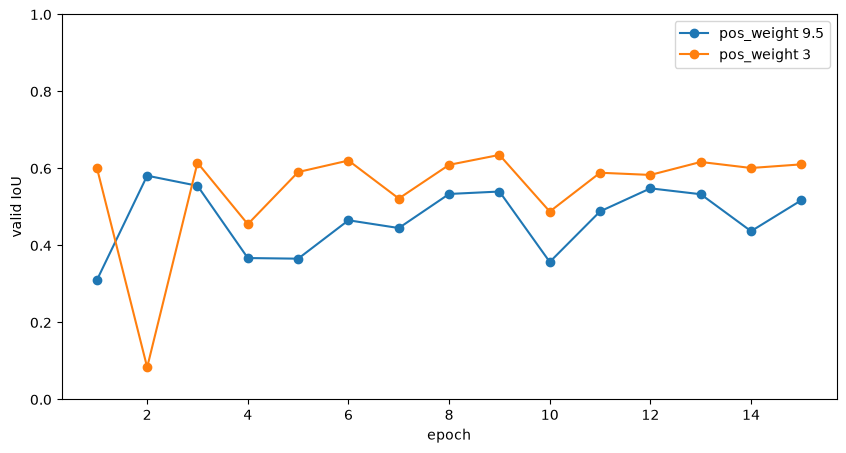

,epoch,train loss,IoU,precision,recall,F1
pos_weight 9.5,2.0,0.66,0.581,0.651,0.845,0.735
pos_weight 3,9.0,0.29,0.635,0.799,0.756,0.777


In [77]:
# Valid IoU at every epoch for the two tries (train losses are not comparable: different pos_weight)
fig, ax = plt.subplots(figsize=(10, 5))
for history, label in [(history_pw9, "pos_weight 9.5"), (history_pw3, "pos_weight 3")]:
    ax.plot(history["epoch"], history["IoU"], marker="o", label=label)
ax.set_xlabel("epoch")
ax.set_ylabel("valid IoU")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

# Best epoch of each try
best = pd.DataFrame({
    "pos_weight 9.5": history_pw9.loc[history_pw9["IoU"].idxmax()],   # row of the epoch with the highest IoU
    "pos_weight 3": history_pw3.loc[history_pw3["IoU"].idxmax()],
}).T
best.round(3)


**pos_weight 3 is better**: best valid IoU **0.635** (epoch 9) against 0.581, with precision **0.80** against 0.65 and recall 0.76 against 0.85. The network makes fewer false alarms and misses a bit more water, and overall the overlap improves.

The valid IoU still drops in a few epochs (2, 7, 10), but we always keep the best epoch, so from now on we use **`model_pw3`**.


## 10. Test on Sen1Floods11

The **test** patches come from the same floods as train and valid, but we never used them for any choice. Now we run the model chosen on valid (`model_pw3`) on them **once**, with the same metrics as before: this is the honest grade of the U-Net on data it has never seen.


In [78]:
# Final exam on Sen1Floods11: test patches, used only once, with the model chosen on valid
water_test = predict(model_pw3, Xp_test)          # (348, 256, 256) True = water
test_metrics = flood_metrics(water_test, yp_test)  # IoU counted over all test pixels together

print(f"valid IoU (best epoch): {history_pw3['IoU'].max():.3f}")
pd.Series(test_metrics).round(3)


valid IoU (best epoch): 0.635


IoU          0.668
precision    0.810
recall       0.793
F1           0.801
dtype: float64

### Comparison with the Sen1Floods11 paper

The paper (Bonafilia et al., 2020) counts IoU differently: it computes the IoU of **every chip** and then takes the average (**mean IoU**), so a chip with a few water pixels weighs as much as a chip full of water. To compare with it, we compute the same number on the **90 full test chips**: the U-Net only uses convolutions, so it also works on 512 × 512 images.


In [79]:
# Mean IoU over the 90 test chips, as in the paper
water_chips = predict(model_pw3, X_test_n)          # (90, 512, 512) True = water

chip_iou = []
for water, chip_labels in zip(water_chips, y_test):
    tp, fp, fn, tn = confusion_counts(water, chip_labels)
    if tp + fp + fn > 0:                            # no water in the label and none predicted → IoU = 0/0, chip skipped
        chip_iou.append(tp / (tp + fp + fn))

print(f"chips used: {len(chip_iou)} of {len(y_test)}")
print(f"U-Net, mean IoU over chips: {np.mean(chip_iou):.3f}")
print("Paper, all water, test set (10 events, no Bolivia):")
print("  FCNN trained on hand labels  0.313")
print("  Otsu threshold on VH         0.359")
print("  best model (Sentinel-2 weak) 0.408")


chips used: 86 of 90
U-Net, mean IoU over chips: 0.414
Paper, all water, test set (10 events, no Bolivia):
  FCNN trained on hand labels  0.313
  Otsu threshold on VH         0.359
  best model (Sentinel-2 weak) 0.408


On the test patches the U-Net gets **IoU 0.668** (precision 0.81, recall 0.79), close to the valid IoU (0.635): choosing the best epoch on valid did not make the model fit valid only.

With the metric of the paper, **mean IoU 0.414**, our small U-Net is above the paper's network trained on hand labels (0.313) and above Otsu on VH (0.359), and at the level of their best model (0.408). The mean IoU is much lower than the IoU over all pixels because chips with only a few water pixels have a low IoU and weigh as much as the others. The comparison is approximate: training setup and the handling of the 4 chips without water (skipped here) are not the same as in the paper.
